In [86]:
import pandas as pd

df = pd.read_csv("matches.csv")
df.head()

,id,season,city,date,match_type,player_of_match,venue,team1,team2,toss_winner,toss_decision,winner,result,result_margin,target_runs,target_overs,super_over,method,umpire1,umpire2
0,335982,2007/08,Bangalore,2008-04-18,League,BB McCullum,M Chinnaswamy Stadium,Royal Challengers Bangalore,Kolkata Knight Riders,Royal Challengers Bangalore,field,Kolkata Knight Riders,runs,140.0,223.0,20.0,N,NaN,Asad Rauf,RE Koertzen
1,335983,2007/08,Chandigarh,2008-04-19,League,MEK Hussey,"Punjab Cricket Association Stadium, Mohali",Kings XI Punjab,Chennai Super Kings,Chennai Super Kings,bat,Chennai Super Kings,runs,33.0,241.0,20.0,N,NaN,MR Benson,SL Shastri
2,335984,2007/08,Delhi,2008-04-19,League,MF Maharoof,Feroz Shah Kotla,Delhi Daredevils,Rajasthan Royals,Rajasthan Royals,bat,Delhi Daredevils,wickets,9.0,130.0,20.0,N,NaN,Aleem Dar,GA Pratapkumar
3,335985,2007/08,Mumbai,2008-04-20,League,MV Boucher,Wankhede Stadium,Mumbai Indians,Royal Challengers Bangalore,Mumbai Indians,bat,Royal Challengers Bangalore,wickets,5.0,166.0,20.0,N,NaN,SJ Davis,DJ Harper
4,335986,2007/08,Kolkata,2008-04-20,League,DJ Hussey,Eden Gardens,Kolkata Knight Riders,Deccan Chargers,Deccan Chargers,bat,Kolkata Knight Riders,wickets,5.0,111.0,20.0,N,NaN,BF Bowden,K Hariharan


In [87]:
df.columns

Index(['id', 'season', 'city', 'date', 'match_type', 'player_of_match',
       'venue', 'team1', 'team2', 'toss_winner', 'toss_decision', 'winner',
       'result', 'result_margin', 'target_runs', 'target_overs', 'super_over',
       'method', 'umpire1', 'umpire2'],
      dtype='object')

In [88]:
df.shape

(1095, 20)

In [89]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1095 entries, 0 to 1094
Data columns (total 20 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id               1095 non-null   int64  
 1   season           1095 non-null   object 
 2   city             1044 non-null   object 
 3   date             1095 non-null   object 
 4   match_type       1095 non-null   object 
 5   player_of_match  1090 non-null   object 
 6   venue            1095 non-null   object 
 7   team1            1095 non-null   object 
 8   team2            1095 non-null   object 
 9   toss_winner      1095 non-null   object 
 10  toss_decision    1095 non-null   object 
 11  winner           1090 non-null   object 
 12  result           1095 non-null   object 
 13  result_margin    1076 non-null   float64
 14  target_runs      1092 non-null   float64
 15  target_overs     1092 non-null   float64
 16  super_over       1095 non-null   object 
 17  method        

In [90]:
df.isnull().sum()

,0
id,0
season,0
city,51
date,0
match_type,0
player_of_match,5
venue,0
team1,0
team2,0
toss_winner,0


In [91]:
df["season"].unique()

array(['2007/08', '2009', '2009/10', '2011', '2012', '2013', '2014',
       '2015', '2016', '2017', '2018', '2019', '2020/21', '2021', '2022',
       '2023', '2024'], dtype=object)

In [92]:
df.duplicated().sum()

np.int64(0)

In [93]:
df["date"] = pd.to_datetime(df["date"])
df["year"] = df["date"].dt.year

df[["season", "date", "year"]].head()

,season,date,year
0,2007/08,2008-04-18,2008
1,2007/08,2008-04-19,2008
2,2007/08,2008-04-19,2008
3,2007/08,2008-04-20,2008
4,2007/08,2008-04-20,2008


In [94]:
df["year"].value_counts().sort_index()

,count
year,
2008,58
2009,57
2010,60
2011,73
2012,74
2013,76
2014,60
2015,59
2016,60


In [95]:
df["team1"].unique()

array(['Royal Challengers Bangalore', 'Kings XI Punjab',
       'Delhi Daredevils', 'Mumbai Indians', 'Kolkata Knight Riders',
       'Rajasthan Royals', 'Deccan Chargers', 'Chennai Super Kings',
       'Kochi Tuskers Kerala', 'Pune Warriors', 'Sunrisers Hyderabad',
       'Gujarat Lions', 'Rising Pune Supergiants',
       'Rising Pune Supergiant', 'Delhi Capitals', 'Punjab Kings',
       'Lucknow Super Giants', 'Gujarat Titans',
       'Royal Challengers Bengaluru'], dtype=object)

In [96]:
team_map = {
    "Royal Challengers Bangalore": "Royal Challengers Bengaluru",
    "Kings XI Punjab": "Punjab Kings",
    "Delhi Daredevils": "Delhi Capitals",
    "Rising Pune Supergiants": "Rising Pune Supergiant",
}

for col in ["team1", "team2", "toss_winner", "winner"]:
    df[col] = df[col].replace(team_map)

df["team1"].unique()

array(['Royal Challengers Bengaluru', 'Punjab Kings', 'Delhi Capitals',
       'Mumbai Indians', 'Kolkata Knight Riders', 'Rajasthan Royals',
       'Deccan Chargers', 'Chennai Super Kings', 'Kochi Tuskers Kerala',
       'Pune Warriors', 'Sunrisers Hyderabad', 'Gujarat Lions',
       'Rising Pune Supergiant', 'Lucknow Super Giants', 'Gujarat Titans'],
      dtype=object)

In [97]:
df["winner"] = df["winner"].fillna("No Result")
df["player_of_match"] = df["player_of_match"].fillna("Unknown")
df["city"] = df["city"].fillna("Unknown")

df.isnull().sum()

,0
id,0
season,0
city,0
date,0
match_type,0
player_of_match,0
venue,0
team1,0
team2,0
toss_winner,0


In [98]:
df["result"].value_counts()

,count
result,
wickets,578
runs,498
tie,14
no result,5


In [99]:
df[["year", "team1", "team2", "toss_winner", "toss_decision", "winner"]].head(10)

,year,team1,team2,toss_winner,toss_decision,winner
0,2008,Royal Challengers Bengaluru,Kolkata Knight Riders,Royal Challengers Bengaluru,field,Kolkata Knight Riders
1,2008,Punjab Kings,Chennai Super Kings,Chennai Super Kings,bat,Chennai Super Kings
2,2008,Delhi Capitals,Rajasthan Royals,Rajasthan Royals,bat,Delhi Capitals
3,2008,Mumbai Indians,Royal Challengers Bengaluru,Mumbai Indians,bat,Royal Challengers Bengaluru
4,2008,Kolkata Knight Riders,Deccan Chargers,Deccan Chargers,bat,Kolkata Knight Riders
5,2008,Rajasthan Royals,Punjab Kings,Punjab Kings,bat,Rajasthan Royals
6,2008,Deccan Chargers,Delhi Capitals,Deccan Chargers,bat,Delhi Capitals
7,2008,Chennai Super Kings,Mumbai Indians,Mumbai Indians,field,Chennai Super Kings
8,2008,Deccan Chargers,Rajasthan Royals,Rajasthan Royals,field,Rajasthan Royals
9,2008,Punjab Kings,Mumbai Indians,Mumbai Indians,field,Punjab Kings


In [100]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

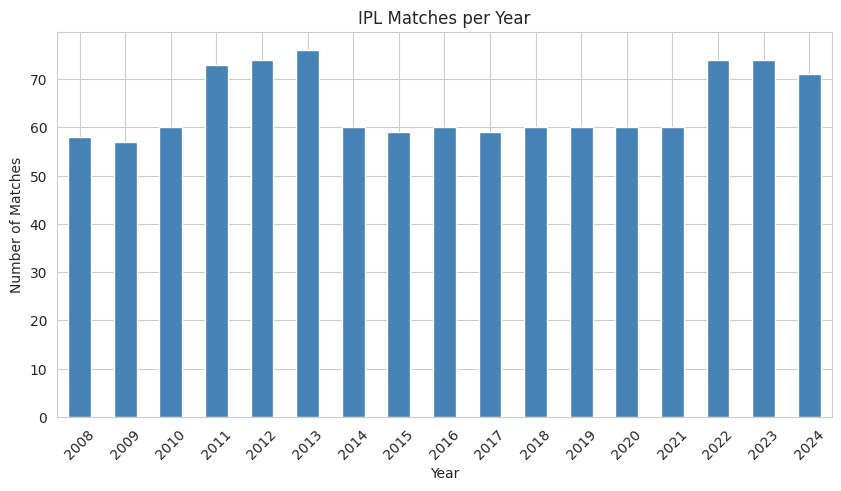

In [101]:
matches_per_year = df["year"].value_counts().sort_index()

matches_per_year.plot(kind="bar", color="steelblue")
plt.title("IPL Matches per Year")
plt.xlabel("Year")
plt.ylabel("Number of Matches")
plt.xticks(rotation=45)
plt.show()

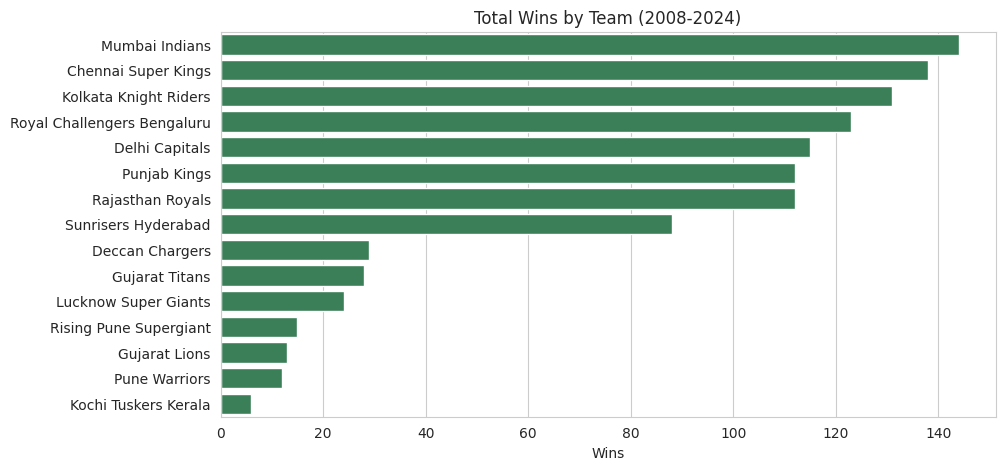

,count
winner,
Mumbai Indians,144
Chennai Super Kings,138
Kolkata Knight Riders,131
Royal Challengers Bengaluru,123
Delhi Capitals,115
Punjab Kings,112
Rajasthan Royals,112
Sunrisers Hyderabad,88
Deccan Chargers,29


In [102]:
wins = df[df["winner"] != "No Result"]["winner"].value_counts()

sns.barplot(x=wins.values, y=wins.index, color="seagreen")
plt.title("Total Wins by Team (2008-2024)")
plt.xlabel("Wins")
plt.ylabel("")
plt.show()

wins

Toss jeetne wali team ne match jeeta: 50.8% times


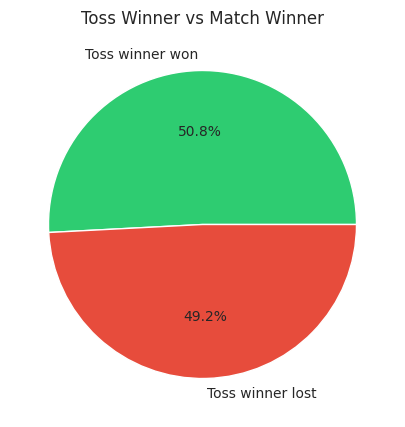

In [103]:
valid = df[df["winner"] != "No Result"].copy()
valid["toss_win_match_win"] = valid["toss_winner"] == valid["winner"]

pct = valid["toss_win_match_win"].mean() * 100
print(f"Toss jeetne wali team ne match jeeta: {pct:.1f}% times")

valid["toss_win_match_win"].value_counts().plot(
    kind="pie",
    labels=["Toss winner won", "Toss winner lost"],
    autopct="%1.1f%%",
    colors=["#2ecc71", "#e74c3c"],
)
plt.title("Toss Winner vs Match Winner")
plt.ylabel("")
plt.show()

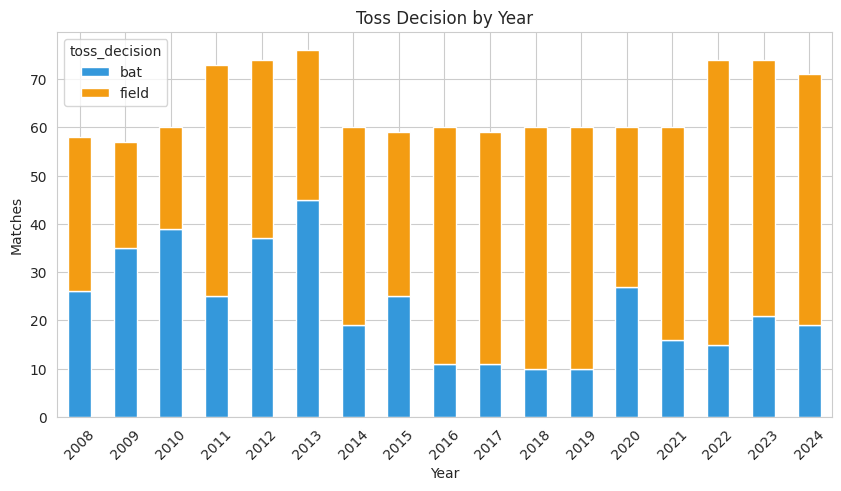

In [104]:
toss_trend = df.groupby(["year", "toss_decision"]).size().unstack(fill_value=0)

toss_trend.plot(kind="bar", stacked=True, color=["#3498db", "#f39c12"])
plt.title("Toss Decision by Year")
plt.xlabel("Year")
plt.ylabel("Matches")
plt.xticks(rotation=45)
plt.show()


Pehle batting karne wali team jeeti: 45.9%
Chase karne wali team jeeti: 54.1%


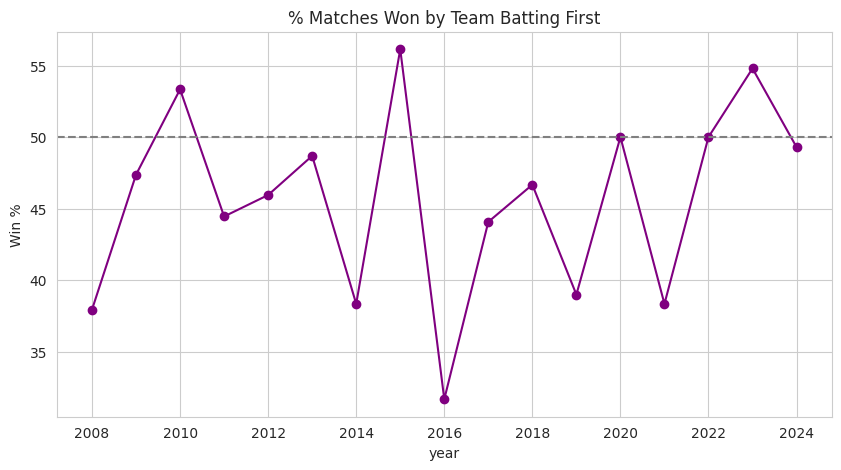

In [105]:
def first_batting_team(row):
    if row["toss_decision"] == "bat":
        return row["toss_winner"]
    return row["team2"] if row["toss_winner"] == row["team1"] else row["team1"]

valid["bat_first_team"] = valid.apply(first_batting_team, axis=1)
valid["bat_first_won"] = valid["bat_first_team"] == valid["winner"]

pct_bat_first = valid["bat_first_won"].mean() * 100
print(f"Pehle batting karne wali team jeeti: {pct_bat_first:.1f}%")
print(f"Chase karne wali team jeeti: {100 - pct_bat_first:.1f}%")

valid.groupby("year")["bat_first_won"].mean().mul(100).plot(marker="o", color="purple")
plt.axhline(50, color="gray", linestyle="--")
plt.title("% Matches Won by Team Batting First")
plt.ylabel("Win %")
plt.show()

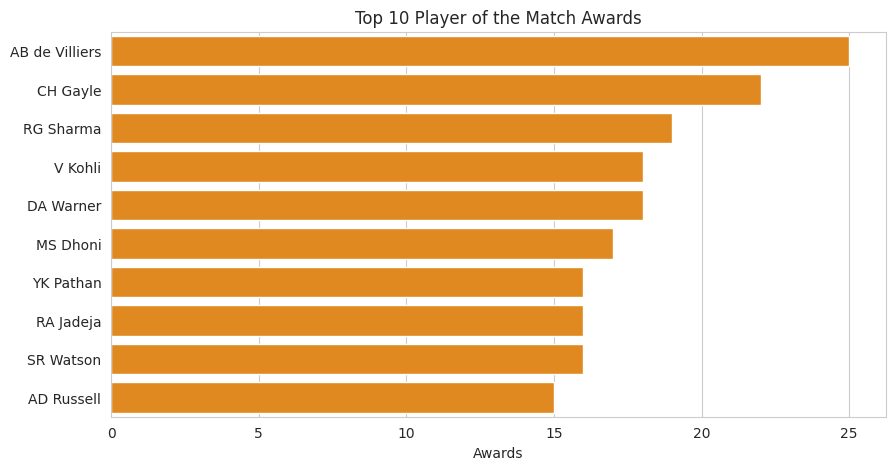

In [106]:
pom = df[df["player_of_match"] != "Unknown"]["player_of_match"].value_counts().head(10)

sns.barplot(x=pom.values, y=pom.index, color="darkorange")
plt.title("Top 10 Player of the Match Awards")
plt.xlabel("Awards")
plt.ylabel("")
plt.show()

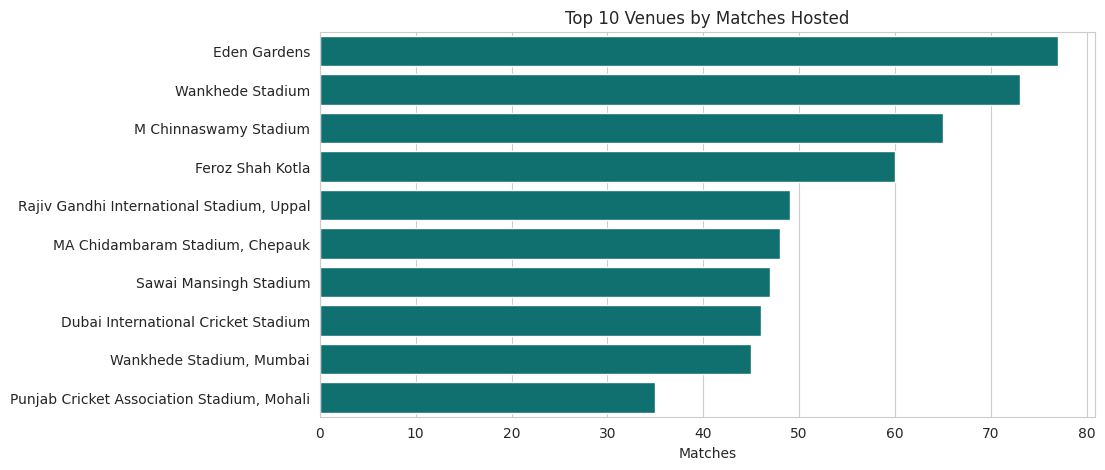

In [107]:
venues = df["venue"].value_counts().head(10)

sns.barplot(x=venues.values, y=venues.index, color="teal")
plt.title("Top 10 Venues by Matches Hosted")
plt.xlabel("Matches")
plt.ylabel("")
plt.show()

In [108]:
# Comma ke baad ka city ka naam hata do
df["venue"] = df["venue"].str.split(",").str[0].str.strip()

# Same stadium ke alag naam ek karna
venue_map = {
    "Punjab Cricket Association IS Bindra Stadium": "Punjab Cricket Association Stadium",
    "Punjab Cricket Association Stadium": "Punjab Cricket Association Stadium",
    "Feroz Shah Kotla": "Arun Jaitley Stadium",
    "Sardar Patel Stadium": "Narendra Modi Stadium",
    "Rajiv Gandhi International Stadium": "Rajiv Gandhi International Stadium",
}
df["venue"] = df["venue"].replace(venue_map)

df["venue"].value_counts().head(12)

,count
venue,
Wankhede Stadium,118
Eden Gardens,93
Arun Jaitley Stadium,90
MA Chidambaram Stadium,85
M Chinnaswamy Stadium,79
Rajiv Gandhi International Stadium,77
Punjab Cricket Association Stadium,61
Sawai Mansingh Stadium,57
Dubai International Cricket Stadium,46


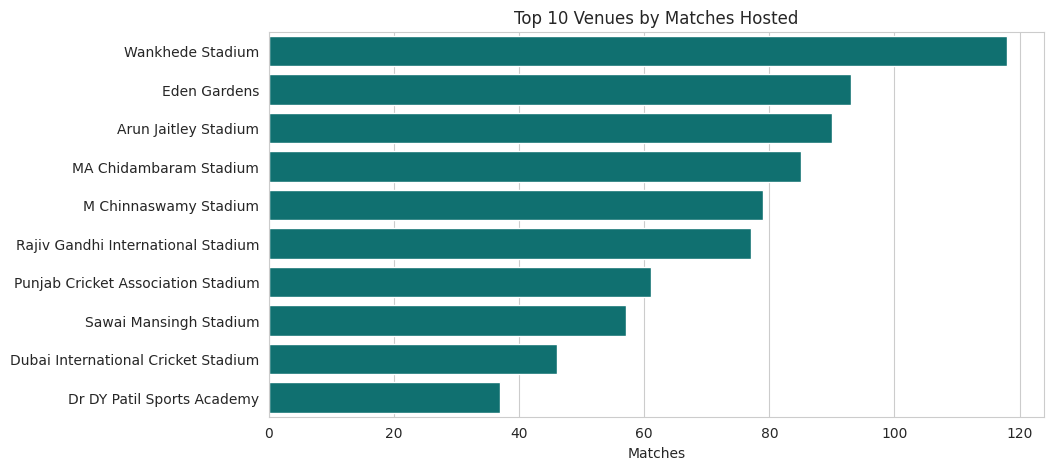

In [109]:
venues = df["venue"].value_counts().head(10)

sns.barplot(x=venues.values, y=venues.index, color="teal")
plt.title("Top 10 Venues by Matches Hosted")
plt.xlabel("Matches")
plt.ylabel("")
plt.show()

In [110]:
import sqlite3

conn = sqlite3.connect(":memory:")
df.to_sql("matches", conn, index=False, if_exists="replace")

1095

In [111]:
q1 = """
SELECT winner, COUNT(*) AS wins
FROM matches
WHERE winner != 'No Result'
GROUP BY winner
ORDER BY wins DESC
LIMIT 5;
"""
pd.read_sql(q1, conn)

,winner,wins
0,Mumbai Indians,144
1,Chennai Super Kings,138
2,Kolkata Knight Riders,131
3,Royal Challengers Bengaluru,123
4,Delhi Capitals,115


In [112]:
q2 = """
SELECT year,
       ROUND(100.0 * SUM(CASE WHEN toss_winner = winner THEN 1 ELSE 0 END) / COUNT(*), 1) AS toss_win_pct
FROM matches
WHERE winner != 'No Result'
GROUP BY year
ORDER BY year;
"""
pd.read_sql(q2, conn)

,year,toss_win_pct
0,2008,48.3
1,2009,57.9
2,2010,51.7
3,2011,52.8
4,2012,44.6
5,2013,47.4
6,2014,50.0
7,2015,49.1
8,2016,56.7
9,2017,57.6


In [113]:
q3 = """
SELECT venue, COUNT(*) AS matches
FROM matches
GROUP BY venue
ORDER BY matches DESC
LIMIT 5;
"""
pd.read_sql(q3, conn)

,venue,matches
0,Wankhede Stadium,118
1,Eden Gardens,93
2,Arun Jaitley Stadium,90
3,MA Chidambaram Stadium,85
4,M Chinnaswamy Stadium,79


## Key Insights

1. **Most successful team:** Mumbai Indians ne sabse zyada matches jeete (144 wins), uske baad Chennai Super Kings (138) aur Kolkata Knight Riders (131).
2. **Toss ka impact kam hai:** Toss jeetne wali team ne sirf 50.8% matches jeete, matlab toss jeetna match jeetne ki guarantee nahi hai.
3. **Chase karna thoda better raha:** Chase karne wali team 54.1% matches jeeti, pehle batting karne wali 45.9%.
4. **Toss decision ka trend badla:** Shuru ke saalon me teams pehle batting choose karti thi, lekin 2016 ke baad zyadatar teams fielding choose karti hain.
5. **Top performers:** AB de Villiers (25 awards) aur CH Gayle (22) ko sabse zyada Player of the Match mile.
6. **Venues:** Eden Gardens, Wankhede aur Chinnaswamy sabse zyada matches host karne wale stadiums hain.
7. **Matches ki ginti:** 2011-13 aur 2022 ke baad matches zyada hue kyunki teams ki sankhya badh gayi thi.

## Conclusion
IPL me toss se zyada important team ki quality aur chase karne ki strategy lagti hai. (Yahan 1-2 line apne words me likho.)